# # Task 04 – Exploratory Data Analysis (EDA)

## Introduction

Exploratory Data Analysis (EDA) is performed to understand the
SmartCare Hospital dataset, identify patterns, examine relationships
between variables, and discover useful insights.

The main objective is to investigate the factors associated with
hospital appointment no-shows.

The target variable is `no_show`, where:
- 1 represents No-Show.
- 0 represents Attended/Other.

# Part 01 -Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Visualization settings
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


# Part 02- Load Dataset

In [3]:
from google.colab import files

uploaded = files.upload()

Saving smartcare_ai_dataset_1000.csv to smartcare_ai_dataset_1000.csv
Saving smartcare_ai_dataset_data_dictionary.csv to smartcare_ai_dataset_data_dictionary.csv


In [4]:
df = pd.read_csv('smartcare_ai_dataset_1000.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (1000, 33)


,record_id,patient_id,age,gender,blood_group,department,diagnosis,appointment_date,waiting_days,previous_appointments,...,consultation_fee_lkr,room_charge_lkr,lab_charge_lkr,medicine_charge_lkr,total_bill_lkr,payment_status,payment_method,no_show,readmitted_30_days,disease_risk_level
0,1,P10001,53,Male,A-,General Medicine,Migraine,2025-04-10,10,1,...,2000,0,0,11596,13596,Paid,Insurance,0,0,High
1,2,P10002,26,Male,B-,General Medicine,Diabetes,2025-05-15,2,3,...,2000,0,0,3652,5652,Paid,Insurance,0,0,Medium
2,3,P10003,22,Male,B+,Orthopedics,Back Pain,2025-07-09,22,7,...,2500,0,1200,2562,6262,Unpaid,Insurance,1,0,Medium
3,4,P10004,44,Female,AB-,Cardiology,Asthma,2025-10-16,16,1,...,2000,0,5000,10262,17262,Paid,Online,0,0,Medium
4,5,P10005,51,Female,O+,Neurology,Hypertension,2025-12-18,12,4,...,4000,0,6000,10414,20414,Paid,Cash,0,0,Medium


# Part 03- Dataset Overview

In [5]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# First five records
display(df.head())

# Last five records
display(df.tail())

Number of rows: 1000
Number of columns: 33

Column Names:
['record_id', 'patient_id', 'age', 'gender', 'blood_group', 'department', 'diagnosis', 'appointment_date', 'waiting_days', 'previous_appointments', 'missed_previous_appointments', 'appointment_status', 'admitted', 'room_type', 'length_of_stay_days', 'previous_admissions', 'systolic_bp', 'diastolic_bp', 'blood_sugar_mg_dl', 'cholesterol_mg_dl', 'bmi', 'lab_tests_count', 'treatments_count', 'consultation_fee_lkr', 'room_charge_lkr', 'lab_charge_lkr', 'medicine_charge_lkr', 'total_bill_lkr', 'payment_status', 'payment_method', 'no_show', 'readmitted_30_days', 'disease_risk_level']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   record_id                     1000 non-null   int64  
 1   patient_id                    1000 non-null   o

,record_id,patient_id,age,gender,blood_group,department,diagnosis,appointment_date,waiting_days,previous_appointments,...,consultation_fee_lkr,room_charge_lkr,lab_charge_lkr,medicine_charge_lkr,total_bill_lkr,payment_status,payment_method,no_show,readmitted_30_days,disease_risk_level
0,1,P10001,53,Male,A-,General Medicine,Migraine,2025-04-10,10,1,...,2000,0,0,11596,13596,Paid,Insurance,0,0,High
1,2,P10002,26,Male,B-,General Medicine,Diabetes,2025-05-15,2,3,...,2000,0,0,3652,5652,Paid,Insurance,0,0,Medium
2,3,P10003,22,Male,B+,Orthopedics,Back Pain,2025-07-09,22,7,...,2500,0,1200,2562,6262,Unpaid,Insurance,1,0,Medium
3,4,P10004,44,Female,AB-,Cardiology,Asthma,2025-10-16,16,1,...,2000,0,5000,10262,17262,Paid,Online,0,0,Medium
4,5,P10005,51,Female,O+,Neurology,Hypertension,2025-12-18,12,4,...,4000,0,6000,10414,20414,Paid,Cash,0,0,Medium


,record_id,patient_id,age,gender,blood_group,department,diagnosis,appointment_date,waiting_days,previous_appointments,...,consultation_fee_lkr,room_charge_lkr,lab_charge_lkr,medicine_charge_lkr,total_bill_lkr,payment_status,payment_method,no_show,readmitted_30_days,disease_risk_level
995,996,P10996,54,Male,AB+,Laboratory Services,Fever,2025-03-24,24,1,...,2000,0,3600,4967,10567,Paid,Card,0,0,High
996,997,P10997,53,Male,O-,Orthopedics,Fracture,2025-05-20,35,4,...,4000,0,3600,6986,14586,Paid,Online,0,0,High
997,998,P10998,26,Male,A+,Cardiology,Chest Pain,2025-02-07,9,3,...,1500,0,12000,11203,24703,Paid,Card,0,1,Medium
998,999,P10999,41,Female,B-,Cardiology,Fracture,2025-07-10,27,1,...,2000,0,2400,5466,9866,Partially Paid,Card,1,0,Medium
999,1000,P11000,22,Female,A-,Radiology,Chest Pain,2025-01-08,17,3,...,2000,0,9000,10705,21705,Paid,Insurance,1,0,Low


#  Part 04-Descriptive Statistics

##  Numerical descriptive statistics

In [6]:
numerical_columns = df.select_dtypes(include=np.number).columns

display(df[numerical_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
record_id,1000.0,500.5000,288.819436,1.0,250.75,500.5,750.25,1000.0
age,1000.0,44.7440,17.851474,1.0,33.00,44.0,57.00,90.0
waiting_days,1000.0,21.8510,13.040892,0.0,11.00,22.0,34.00,44.0
previous_appointments,1000.0,2.8840,1.693343,0.0,2.00,3.0,4.00,10.0
missed_previous_appointments,1000.0,0.5530,0.740094,0.0,0.00,0.0,1.00,4.0
admitted,1000.0,0.3300,0.470448,0.0,0.00,0.0,1.00,1.0
length_of_stay_days,1000.0,1.1030,1.885191,0.0,0.00,0.0,2.00,9.0
previous_admissions,1000.0,0.8550,0.958590,0.0,0.00,1.0,1.00,5.0
systolic_bp,1000.0,128.4230,15.486895,85.0,117.00,128.0,139.00,178.0
diastolic_bp,1000.0,78.8280,10.043669,50.0,72.00,79.0,86.00,111.0


##  Categorical descriptive statistics

In [7]:
categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

display(df[categorical_columns].describe().T)

,count,unique,top,freq
patient_id,1000,1000,P10001,1
gender,1000,2,Male,501
blood_group,1000,8,AB-,136
department,1000,7,General Medicine,159
diagnosis,1000,10,Pneumonia,115
appointment_date,1000,339,2025-08-08,8
appointment_status,1000,4,No-Show,495
room_type,94,3,General Ward,52
payment_status,1000,3,Paid,668
payment_method,1000,4,Insurance,259


## Mean, median and standard deviation

In [8]:
stats = df[numerical_columns].agg(
    ['mean', 'median', 'std', 'min', 'max']
).T

display(stats)

,mean,median,std,min,max
record_id,500.5000,500.5,288.819436,1.0,1000.0
age,44.7440,44.0,17.851474,1.0,90.0
waiting_days,21.8510,22.0,13.040892,0.0,44.0
previous_appointments,2.8840,3.0,1.693343,0.0,10.0
missed_previous_appointments,0.5530,0.0,0.740094,0.0,4.0
admitted,0.3300,0.0,0.470448,0.0,1.0
length_of_stay_days,1.1030,0.0,1.885191,0.0,9.0
previous_admissions,0.8550,1.0,0.958590,0.0,5.0
systolic_bp,128.4230,128.0,15.486895,85.0,178.0
diastolic_bp,78.8280,79.0,10.043669,50.0,111.0


# Part 05-Missing Values Analysis

In [9]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': (missing_values / len(df)) * 100
})

missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(by='Missing Percentage', ascending=False)

display(missing_summary)

,Missing Values,Missing Percentage
room_type,906,90.6


##Visualize missing values

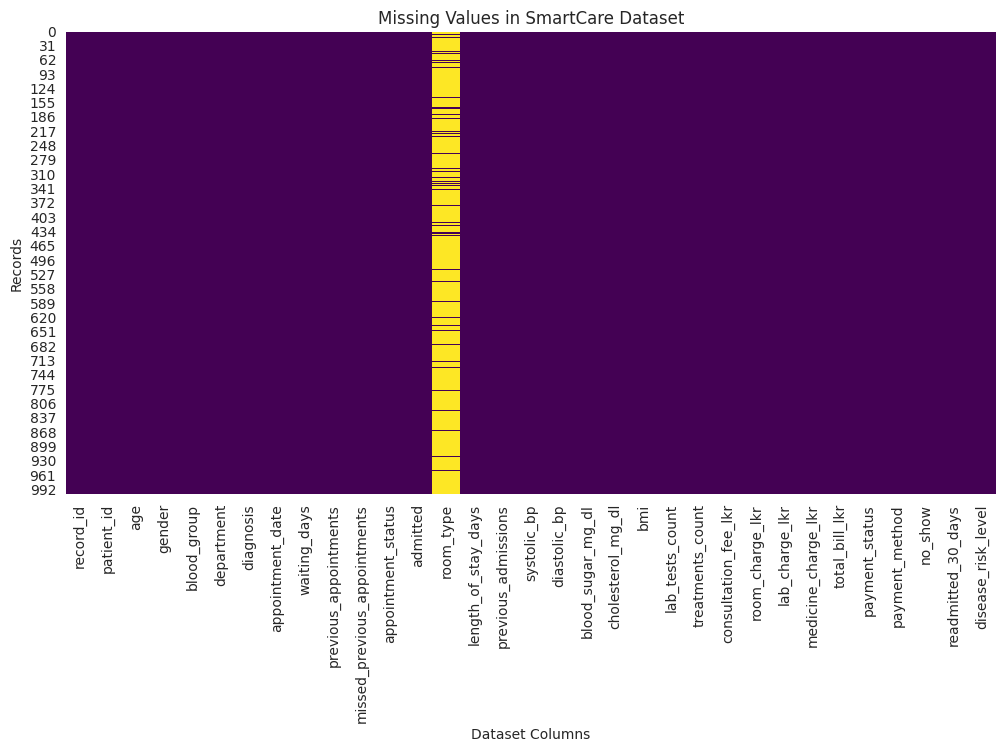

In [10]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap='viridis'
)

plt.title('Missing Values in SmartCare Dataset')
plt.xlabel('Dataset Columns')
plt.ylabel('Records')
plt.show()

# Part 06-Class Distribution Analysis

##  Count the target classes

In [11]:
print("No-Show Class Distribution:")
print(df['no_show'].value_counts())

print("\nClass Percentages:")
print(df['no_show'].value_counts(normalize=True) * 100)

No-Show Class Distribution:
no_show
0    505
1    495
Name: count, dtype: int64

Class Percentages:
no_show
0    50.5
1    49.5
Name: proportion, dtype: float64


##  Class distribution chart

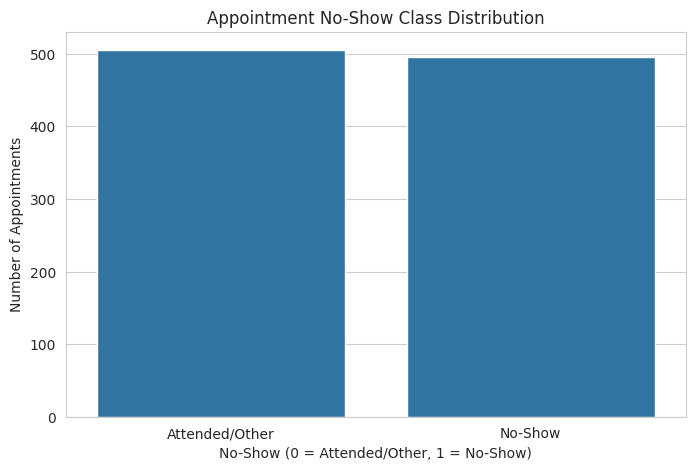

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='no_show'
)

plt.title('Appointment No-Show Class Distribution')
plt.xlabel('No-Show (0 = Attended/Other, 1 = No-Show)')
plt.ylabel('Number of Appointments')
plt.xticks([0, 1], ['Attended/Other', 'No-Show'])

plt.show()

##  Pie chart

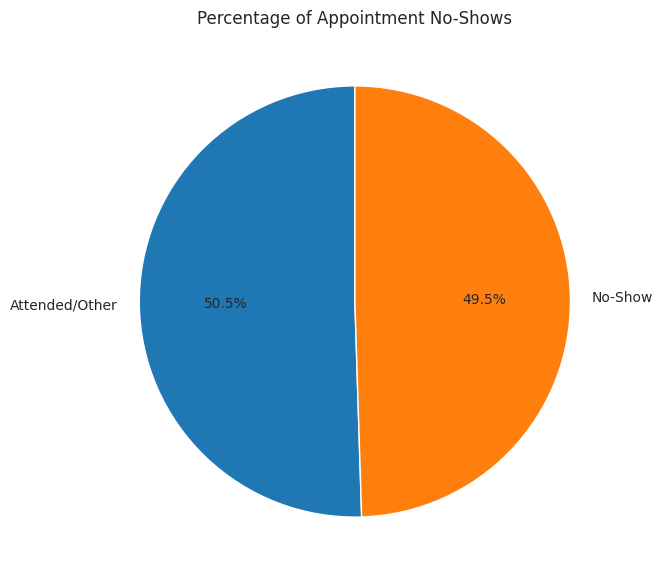

In [13]:
class_counts = df['no_show'].value_counts().sort_index()

plt.figure(figsize=(7, 7))

plt.pie(
    class_counts,
    labels=['Attended/Other', 'No-Show'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Percentage of Appointment No-Shows')
plt.show()


### Interpretation

The dataset contains approximately **495 No-Show records (49.5%)** and **505 Attended/Other records (50.5%)**.

The two classes are almost equally distributed. Therefore, there is **no significant class imbalance** in the dataset.


# Part 07 -Distribution Analysis – Histograms

##  Age distribution

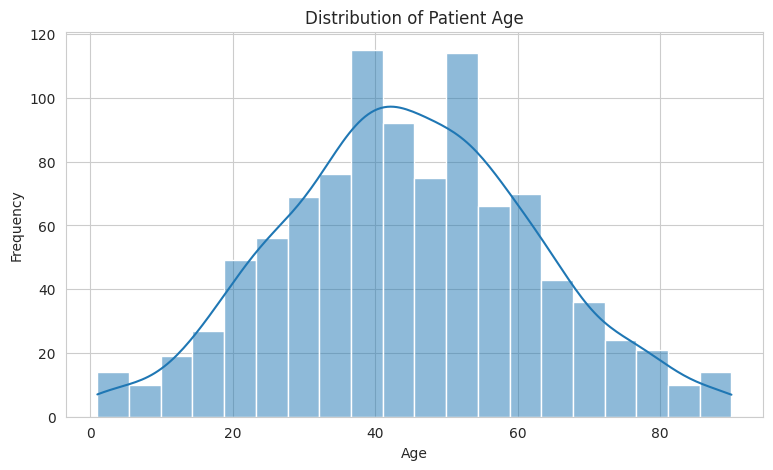

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='age',
    bins=20,
    kde=True
)

plt.title('Distribution of Patient Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

##  Waiting days distribution

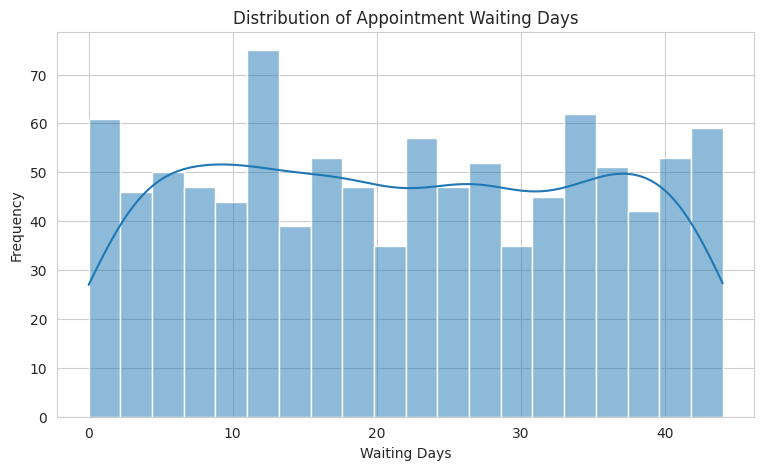

In [15]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='waiting_days',
    bins=20,
    kde=True
)

plt.title('Distribution of Appointment Waiting Days')
plt.xlabel('Waiting Days')
plt.ylabel('Frequency')
plt.show()

##  Previous appointments distribution

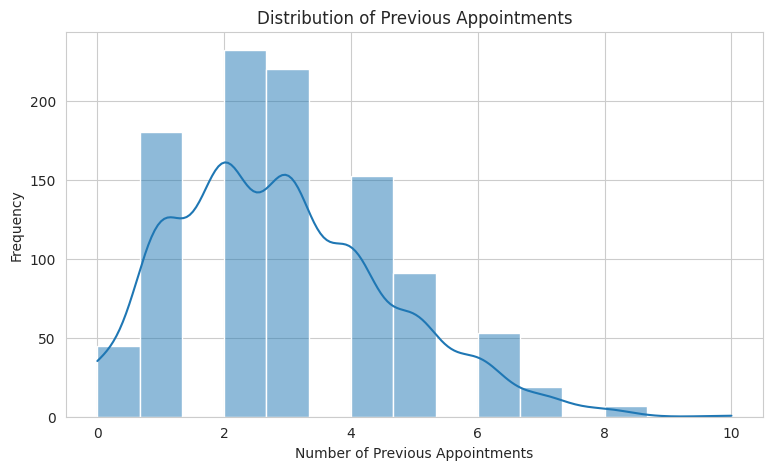

In [16]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='previous_appointments',
    bins=15,
    kde=True
)

plt.title('Distribution of Previous Appointments')
plt.xlabel('Number of Previous Appointments')
plt.ylabel('Frequency')
plt.show()

##  Missed previous appointments distribution

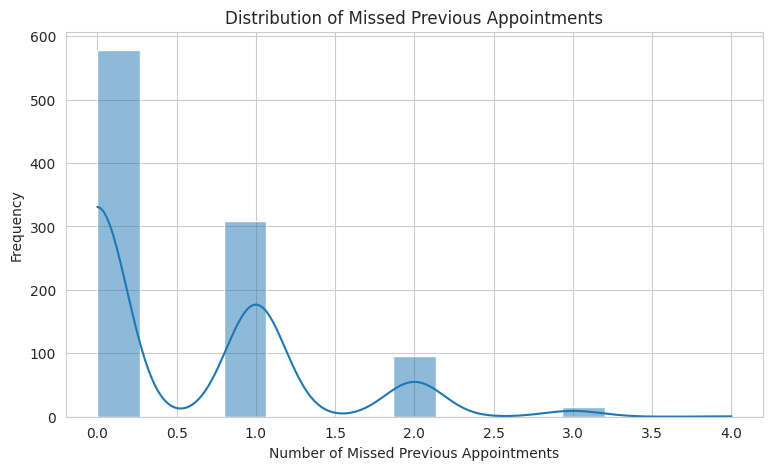

In [17]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='missed_previous_appointments',
    bins=15,
    kde=True
)

plt.title('Distribution of Missed Previous Appointments')
plt.xlabel('Number of Missed Previous Appointments')
plt.ylabel('Frequency')
plt.show()

# Part 08- Outlier Analysis – Boxplots

##  Age boxplot

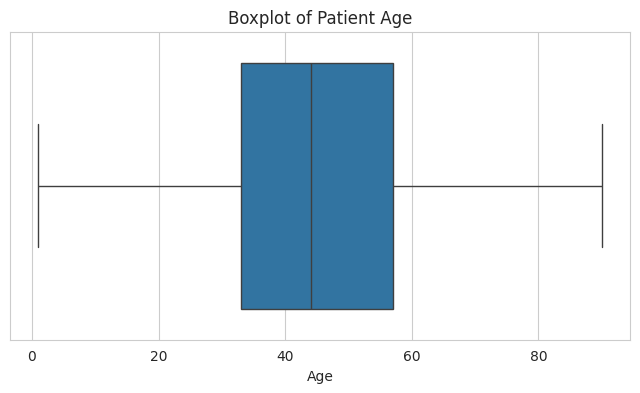

In [18]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x='age')

plt.title('Boxplot of Patient Age')
plt.xlabel('Age')
plt.show()

##  Waiting days boxplot

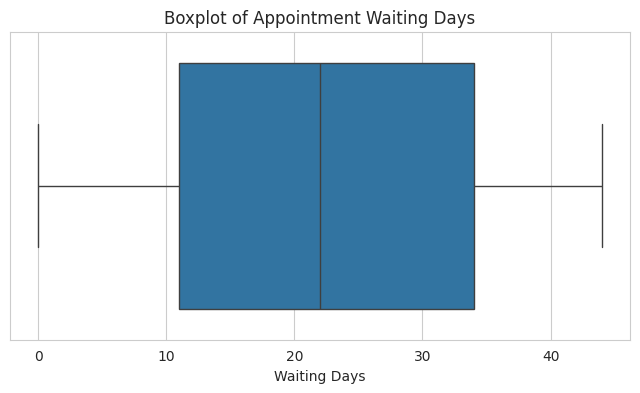

In [19]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x='waiting_days')

plt.title('Boxplot of Appointment Waiting Days')
plt.xlabel('Waiting Days')
plt.show()

## Previous missed appointments boxplot

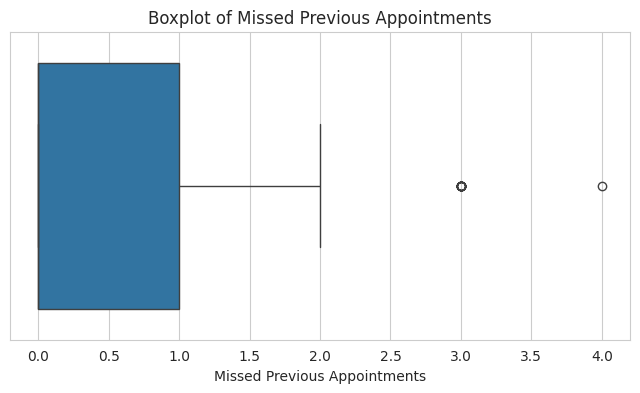

In [20]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    data=df,
    x='missed_previous_appointments'
)

plt.title('Boxplot of Missed Previous Appointments')
plt.xlabel('Missed Previous Appointments')
plt.show()

##  Generate an outlier summary using IQR

In [21]:
outlier_results = []

for col in ['age', 'waiting_days',
            'previous_appointments',
            'missed_previous_appointments']:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_results.append({
        'Feature': col,
        'Lower Bound': lower,
        'Upper Bound': upper,
        'Outlier Count': count
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)

,Feature,Lower Bound,Upper Bound,Outlier Count
0,age,-3.0,93.0,0
1,waiting_days,-23.5,68.5,0
2,previous_appointments,-1.0,7.0,8
3,missed_previous_appointments,-1.5,2.5,17


###  Outliers should be investigated rather than automatically deleted. Some unusually high values may represent valid patient histories or long waiting periods.

#  Part 09 -Correlation Analysis

##  Correlation matrix

In [22]:
correlation_columns = [
    'age',
    'waiting_days',
    'previous_appointments',
    'missed_previous_appointments',
    'previous_admissions',
    'no_show'
]

correlation_matrix = df[correlation_columns].corr()

display(correlation_matrix)

,age,waiting_days,previous_appointments,missed_previous_appointments,previous_admissions,no_show
age,1.000000,-0.033049,0.010143,-0.056024,-0.078275,-0.062694
waiting_days,-0.033049,1.000000,0.032579,-0.025888,-0.015503,0.242564
previous_appointments,0.010143,0.032579,1.000000,0.373926,-0.010989,-0.082226
missed_previous_appointments,-0.056024,-0.025888,0.373926,1.000000,0.015782,0.087240
previous_admissions,-0.078275,-0.015503,-0.010989,0.015782,1.000000,-0.010907
no_show,-0.062694,0.242564,-0.082226,0.087240,-0.010907,1.000000


## Correlation heatmap

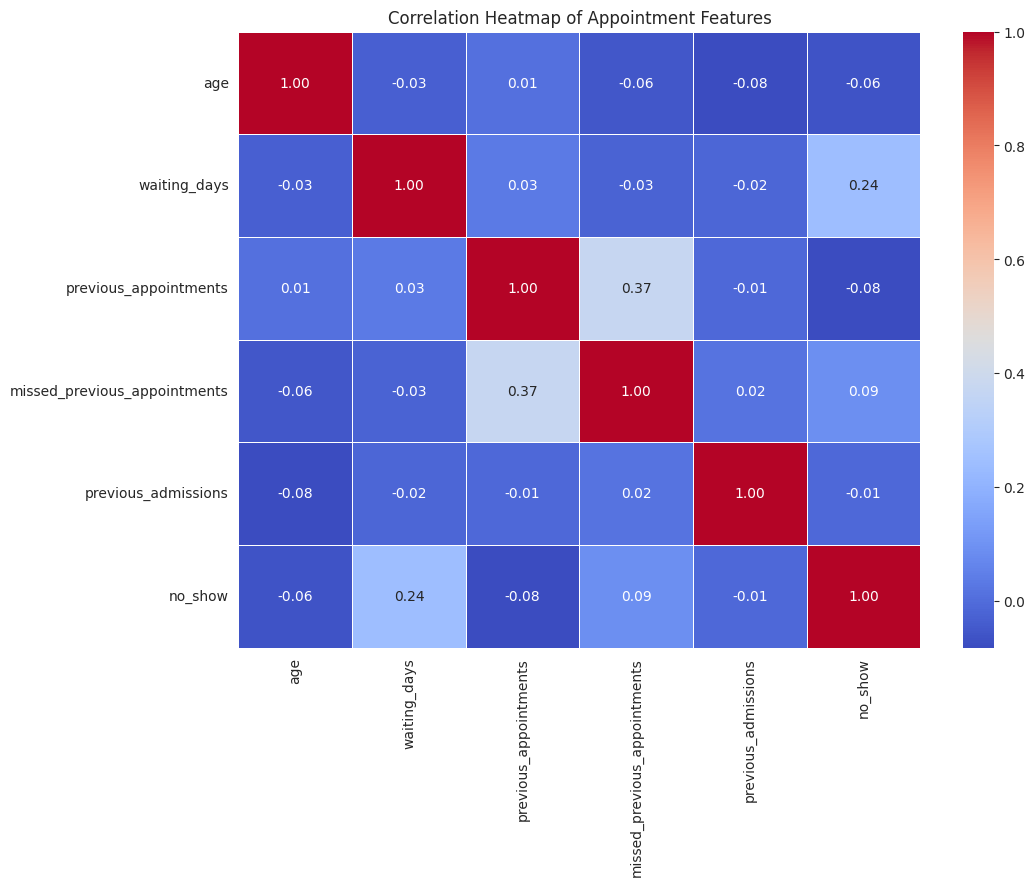

In [23]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Appointment Features')
plt.show()

##  Correlation with the target variable

In [24]:
target_correlation = (
    correlation_matrix['no_show']
    .drop('no_show')
    .sort_values(ascending=False)
)

display(target_correlation)

,no_show
waiting_days,0.242564
missed_previous_appointments,0.087240
previous_admissions,-0.010907
age,-0.062694
previous_appointments,-0.082226


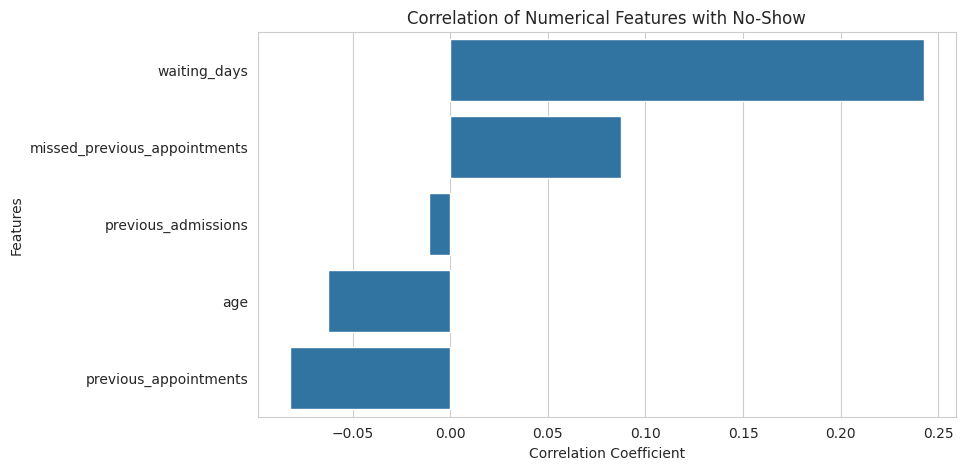

In [25]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=target_correlation.values,
    y=target_correlation.index
)

plt.title('Correlation of Numerical Features with No-Show')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Features')
plt.show()

# Part 10-Relationship Analysis – Scatterplots

##  Age vs waiting days

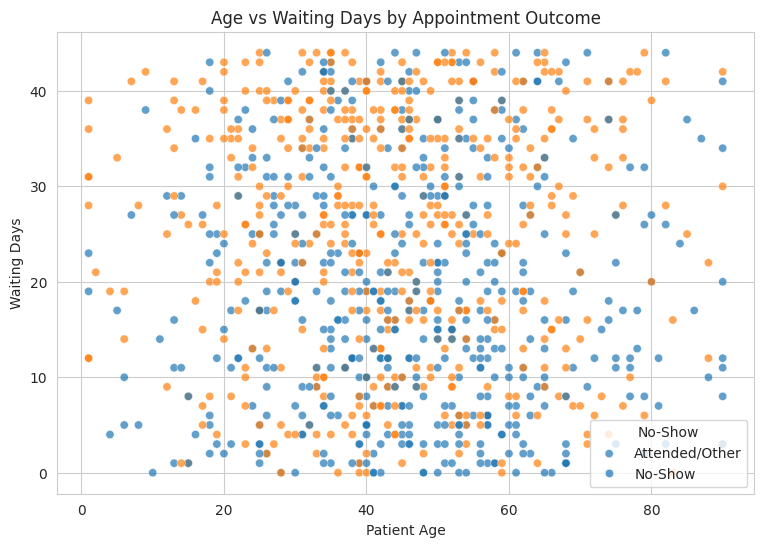

In [26]:
 plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='age',
    y='waiting_days',
    hue='no_show',
    alpha=0.7
)

plt.title('Age vs Waiting Days by Appointment Outcome')
plt.xlabel('Patient Age')
plt.ylabel('Waiting Days')
plt.legend(title='No-Show', labels=['Attended/Other', 'No-Show'])
plt.show()

##  Previous appointments vs missed previous appointments

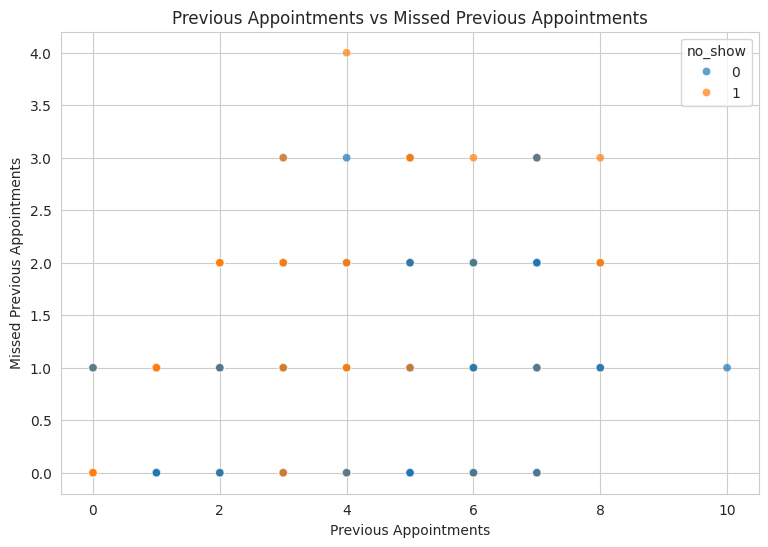

In [27]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='previous_appointments',
    y='missed_previous_appointments',
    hue='no_show',
    alpha=0.7
)

plt.title('Previous Appointments vs Missed Previous Appointments')
plt.xlabel('Previous Appointments')
plt.ylabel('Missed Previous Appointments')
plt.show()

##  Waiting days vs missed previous appointments

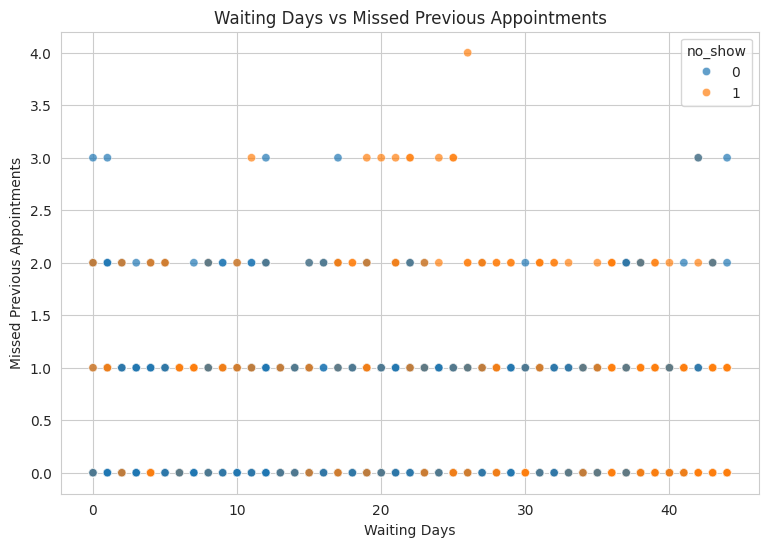

In [28]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='waiting_days',
    y='missed_previous_appointments',
    hue='no_show',
    alpha=0.7
)

plt.title('Waiting Days vs Missed Previous Appointments')
plt.xlabel('Waiting Days')
plt.ylabel('Missed Previous Appointments')
plt.show()

#Part 11- Pattern Discovery

## No-show rate by department

,department,No-Show Rate (%)
0,Neurology,54.729730
1,Cardiology,53.164557
2,Radiology,49.285714
3,Laboratory Services,49.137931
4,General Medicine,49.056604
5,Pediatrics,47.826087
6,Orthopedics,42.553191


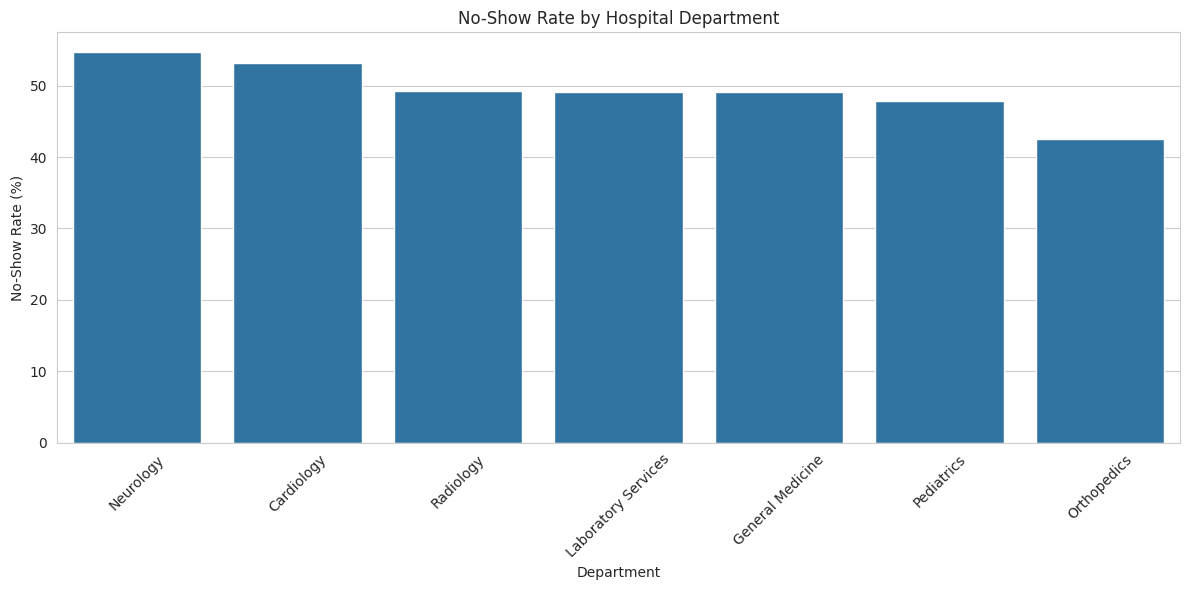

In [29]:
department_no_show = (
    df.groupby('department')['no_show']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .reset_index(name='No-Show Rate (%)')
)

display(department_no_show)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=department_no_show,
    x='department',
    y='No-Show Rate (%)'
)

plt.title('No-Show Rate by Hospital Department')
plt.xlabel('Department')
plt.ylabel('No-Show Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##  No-show rate by gender

,gender,No-Show Rate (%)
0,Female,49.498998
1,Male,49.500998


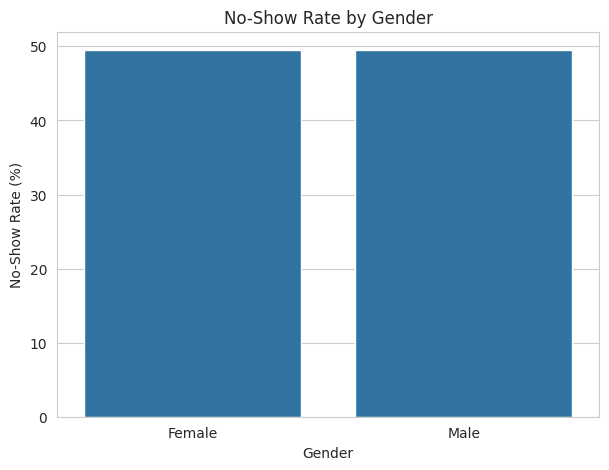

In [31]:
gender_no_show = (
    df.groupby('gender')['no_show']
    .mean()
    .mul(100)
    .reset_index(name='No-Show Rate (%)')
)

display(gender_no_show)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=gender_no_show,
    x='gender',
    y='No-Show Rate (%)'
)

plt.title('No-Show Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('No-Show Rate (%)')
plt.show()

## No-show rate by waiting period

,waiting_period_category,No-Show Rate (%)
0,0–7 days,33.516484
1,8–14 days,39.375000
2,15–30 days,48.843931
3,Above 30 days,64.743590


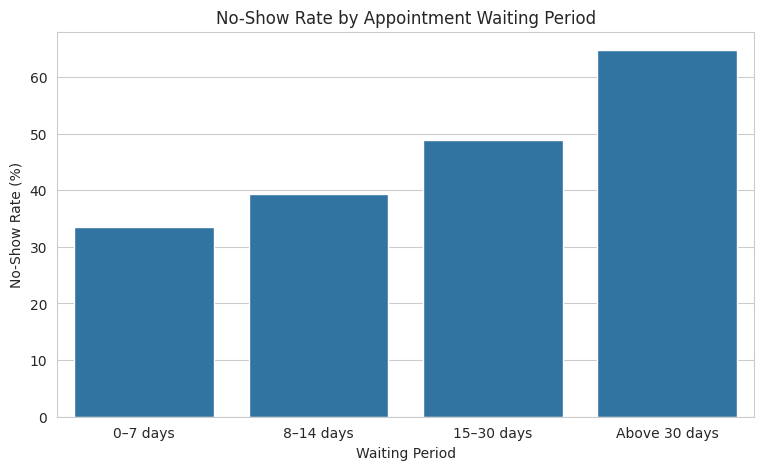

In [32]:
df['waiting_period_category'] = pd.cut(
    df['waiting_days'],
    bins=[-1, 7, 14, 30, float('inf')],
    labels=['0–7 days', '8–14 days', '15–30 days', 'Above 30 days']
)

waiting_no_show = (
    df.groupby('waiting_period_category', observed=False)['no_show']
    .mean()
    .mul(100)
    .reset_index(name='No-Show Rate (%)')
)

display(waiting_no_show)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=waiting_no_show,
    x='waiting_period_category',
    y='No-Show Rate (%)'
)

plt.title('No-Show Rate by Appointment Waiting Period')
plt.xlabel('Waiting Period')
plt.ylabel('No-Show Rate (%)')
plt.show()

##  No-show rate by previous missed appointments

,missed_previous_appointments,No-Show Rate (%)
0,0,46.020761
1,1,53.074434
2,2,56.250000
3,3,62.500000
4,4,100.000000


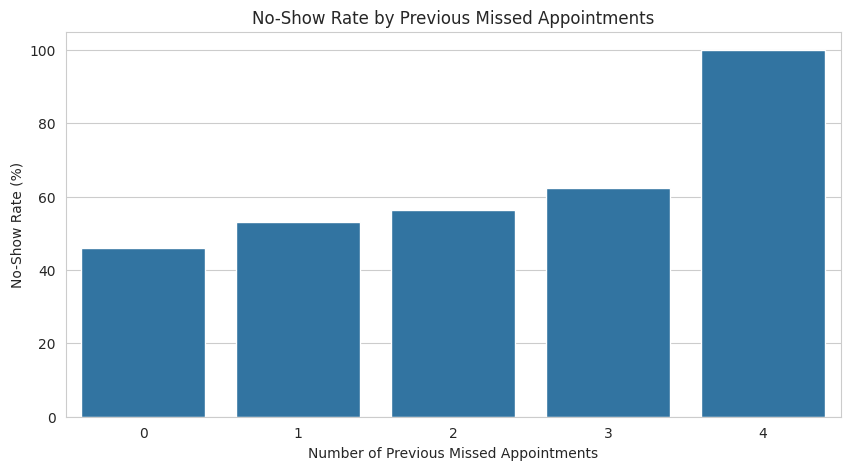

In [33]:
missed_no_show = (
    df.groupby('missed_previous_appointments')['no_show']
    .mean()
    .mul(100)
    .reset_index(name='No-Show Rate (%)')
)

display(missed_no_show)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=missed_no_show,
    x='missed_previous_appointments',
    y='No-Show Rate (%)'
)

plt.title('No-Show Rate by Previous Missed Appointments')
plt.xlabel('Number of Previous Missed Appointments')
plt.ylabel('No-Show Rate (%)')
plt.show()

##   Appointment patterns by day of the week

,appointment_day,No-Show Rate (%)
0,Monday,42.028986
1,Tuesday,45.517241
2,Wednesday,51.748252
3,Thursday,50.000000
4,Friday,56.617647
5,Saturday,53.103448
6,Sunday,47.445255


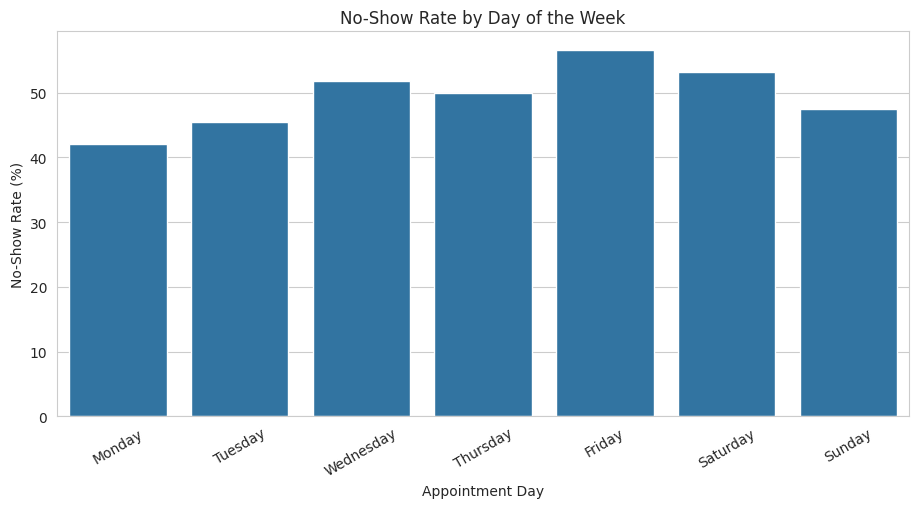

In [34]:
df['appointment_date'] = pd.to_datetime(
    df['appointment_date'],
    errors='coerce'
)

df['appointment_day'] = df['appointment_date'].dt.day_name()

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

day_no_show = (
    df.groupby('appointment_day')['no_show']
    .mean()
    .mul(100)
    .reindex(day_order)
    .reset_index(name='No-Show Rate (%)')
)

display(day_no_show)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=day_no_show,
    x='appointment_day',
    y='No-Show Rate (%)'
)

plt.title('No-Show Rate by Day of the Week')
plt.xlabel('Appointment Day')
plt.ylabel('No-Show Rate (%)')
plt.xticks(rotation=30)
plt.show()

# Part 12 -Key Findings and Interpretation

In [36]:
# Calculate age_no_show to fix the NameError
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 18, 35, 50, 65, float('inf')],
    labels=['0–18', '19–35', '36–50', '51–65', 'Above 65']
)

age_no_show = (
    df.groupby('age_group', observed=False)['no_show']
    .mean()
    .mul(100)
    .reset_index(name='No-Show Rate (%)')
)

print("========== EDA KEY FINDINGS ==========")

print("\n1. Total Appointments:")
print(len(df))

print("\n2. Total No-Show Appointments:")
print((df['no_show'] == 1).sum())

print("\n3. Total Attended/Other Appointments:")
print((df['no_show'] == 0).sum())

print("\n4. Overall No-Show Rate:")
print(round(df['no_show'].mean() * 100, 2), "%")

print("\n5. Average Patient Age:")
print(round(df['age'].mean(), 2))

print("\n6. Average Waiting Days:")
print(round(df['waiting_days'].mean(), 2))

print("\n7. Average Previous Missed Appointments:")
print(round(df['missed_previous_appointments'].mean(), 2))

print("\n8. Department with Highest Observed No-Show Rate:")
print(department_no_show.iloc[0])

print("\n9. Waiting Period with Highest Observed No-Show Rate:")
print(waiting_no_show.loc[
    waiting_no_show['No-Show Rate (%)'].idxmax()
])

print("\n10. Age Group with Highest Observed No-Show Rate:")
print(age_no_show.loc[
    age_no_show['No-Show Rate (%)'].idxmax()
])

========== EDA KEY FINDINGS ==========

1. Total Appointments:
1000

2. Total No-Show Appointments:
495

3. Total Attended/Other Appointments:
505

4. Overall No-Show Rate:
49.5 %

5. Average Patient Age:
44.74

6. Average Waiting Days:
21.85

7. Average Previous Missed Appointments:
0.55

8. Department with Highest Observed No-Show Rate:
department          Neurology
No-Show Rate (%)     54.72973
Name: 0, dtype: object

9. Waiting Period with Highest Observed No-Show Rate:
waiting_period_category    Above 30 days
No-Show Rate (%)                64.74359
Name: 3, dtype: object

10. Age Group with Highest Observed No-Show Rate:
age_group                0–18
No-Show Rate (%)    54.285714
Name: 0, dtype: object


# Part 13-Save EDA visualizations

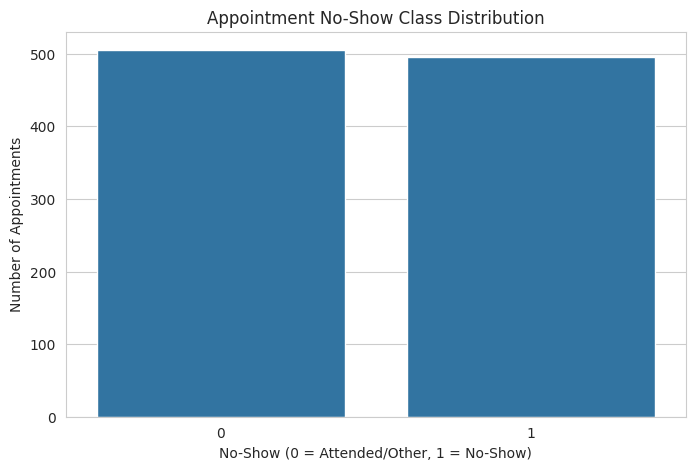

In [37]:
import os

eda_folder = '/content/smartcare-hospital-ai/reports/figures/eda'

os.makedirs(eda_folder, exist_ok=True)

# Example: Save the class distribution chart
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='no_show')

plt.title('Appointment No-Show Class Distribution')
plt.xlabel('No-Show (0 = Attended/Other, 1 = No-Show)')
plt.ylabel('Number of Appointments')

plt.savefig(
    f'{eda_folder}/class_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [38]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    '/content/EDA_visualizations',
    'zip',
    eda_folder
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>